---
title: "Entropy and the Second Law — Level 2"
short_title: "03 Entropy & the Second Law"
numbering:
  heading_2: true
  equation: true
---

# Entropy and the Second Law

:::{seealso} Math for this topic
- [T-M1: Counting, probability and Stirling's approximation](../math/01-counting-probability-stirling.ipynb)
- [M3: Multivariable calculus](../../level2-book/math/03-multivariable-calculus.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 20 | dS = dQ/T for simple processes |
| **2** | **Schroeder, ch. 2–3** | **Entropy as ln(multiplicity), the Einstein solid, temperature from dS/dU** |
| 3 | Pathria, ch. 1–2 | Microcanonical ensemble, Gibbs entropy, Liouville's theorem, ergodicity |

The new skill at this level: deriving the second law by counting microstates, and defining temperature from entropy instead of the other way round

Math for this topic: T-M1 (counting and Stirling), mechanics M3 (partial derivatives) and M1 (Taylor series).
:::

Workbook example ladder: entropy change of mixing → multiplicity of an Einstein solid → microcanonical entropy of N free particles. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Einstein Solid

Model a solid as $N$ independent quantum oscillators, all with the same frequency. Each oscillator's energy comes in units of $\epsilon = hf$, so the solid's thermal energy is $U = q\epsilon$ for some integer $q$. The macrostate is $(N, q)$; a microstate says how many units each oscillator holds. The count of microstates is stars and bars (T-M1, {eq}`eq-stars-bars`):

$$
\Omega(N, q) = \binom{q + N - 1}{q} = \frac{(q + N - 1)!}{q!\,(N - 1)!} .
$$ (eq-einstein-multiplicity)

$\Omega$ grows ferociously. Three oscillators sharing 3 units have 10 microstates; $N = 10^{23}$ oscillators with $q = 10^{23}$ units have about $2^{2\times10^{23}}$.

## Two Solids in Contact

Now let two Einstein solids $A$ and $B$ exchange energy, with $q_A + q_B = q$ fixed. Assume the **fundamental postulate**: in an isolated system in equilibrium, every accessible microstate is equally probable. Then the probability of a given split is proportional to its multiplicity,

$$
P(q_A)\propto\Omega_A(q_A)\,\Omega_B(q - q_A) .
$$ (eq-two-solids)

For small solids the distribution is broad. For large ones it becomes a spike.

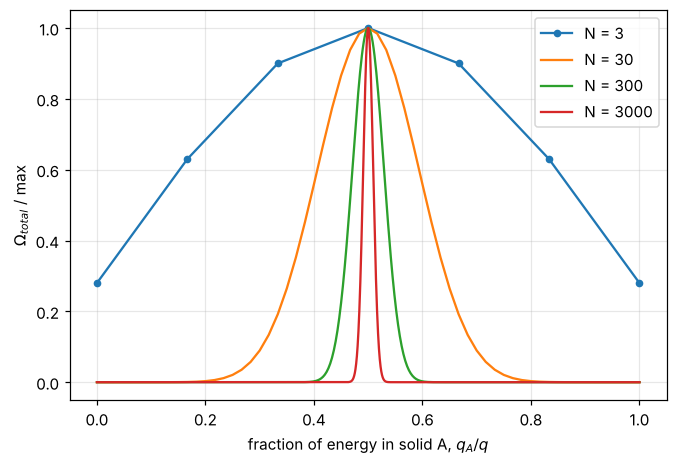

In [2]:
#| label: fig-two-solids
#| caption: "Probability of each energy split between two identical Einstein solids sharing q = 2N energy units, plotted against q_A/q. With N = 3 any split is plausible; with N = 3000 the energy is almost certainly within a percent or two of an even split. For N ~ 10²³ the peak's relative width is about 10⁻¹²."
from scipy.special import gammaln
def lnOmega(N, q):
    return gammaln(q + N) - gammaln(q + 1) - gammaln(N)
fig, ax = plt.subplots()
for N, col in [(3, "tab:blue"), (30, "tab:orange"), (300, "tab:green"), (3000, "tab:red")]:
    q = 2 * N
    qA = np.arange(q + 1)
    lnP = lnOmega(N, qA) + lnOmega(N, q - qA)
    P = np.exp(lnP - lnP.max())
    ax.plot(qA / q, P, "o-" if N == 3 else "-", ms=4, color=col, label=f"N = {N}")
ax.set_xlabel("fraction of energy in solid A, $q_A/q$"); ax.set_ylabel("$\\Omega_{total}$ / max"); ax.legend(); plt.show()

This is the **second law** in its statistical form: an isolated macroscopic system moves toward the macrostate with the largest multiplicity and stays there, because that macrostate has overwhelmingly more microstates than all the others. Nothing forbids heat flowing from cold to hot; it is just so improbable that it never happens for $10^{23}$ particles.

## Entropy

Multiplicities multiply when systems are combined; it is more convenient to have a quantity that adds.

:::{prf:definition} Entropy
:label: def-entropy

$$
S = k\ln\Omega .
$$ (eq-boltzmann-entropy)
:::

For combined systems $S_{\text{total}} = S_A + S_B$, and the second law reads: **the total entropy of an isolated system tends to increase.** Because $\Omega$ is a very large number (T-M1), $S/k$ is merely large, of order $N$.

::::{prf:example} Entropy of the Einstein solid at high temperature
:label: ex-einstein-entropy

Find $S$ for $q\gg N\gg1$.

:::{dropdown} Solution
With Stirling ($\ln n!\approx n\ln n - n$) and $q + N - 1\approx q + N$:

$$
\frac{S}{k}\approx(q + N)\ln(q + N) - q\ln q - N\ln N .
$$

For $q\gg N$, write $\ln(q + N) = \ln q + \ln(1 + N/q)\approx\ln q + N/q$:

$$
\frac Sk\approx N\ln\frac qN + N = N\ln\frac{U}{N\epsilon} + N .
$$

Entropy grows logarithmically with energy, a pattern that recurs for every system in the high-temperature limit.
:::
::::

## Temperature from Entropy

Two systems in thermal contact reach equilibrium at the split $U_A$ that maximizes $S_A(U_A) + S_B(U - U_A)$:

$$
\frac{\partial S_A}{\partial U_A} = \frac{\partial S_B}{\partial U_B} .
$$

The quantity that is equal at equilibrium is temperature (topic 1), so it must be a function of $\partial S/\partial U$. Choosing the function that matches the ideal-gas scale gives the definition:

$$
\frac1T = \left(\frac{\partial S}{\partial U}\right)_{N, V} .
$$ (eq-temperature-def)

Energy flows toward the system with the *steeper* $S(U)$, because a unit of energy buys it more entropy than the other system loses. Steep $S(U)$ means low $T$: energy flows from hot to cold, derived instead of assumed.

In [3]:
# Temperature of the Einstein solid from the exact (Stirling) entropy, solved for U(T)
q, N, eps, k, T = sp.symbols("q N epsilon k T", positive=True)
S = k * ((q + N) * sp.log(q + N) - q * sp.log(q) - N * sp.log(N))
invT = sp.factor_terms(sp.expand_log(sp.diff(S, q) / eps, force=True))   # dS/dU with U = q*eps
display(Math(r"\frac{1}{T} = \frac{\partial S}{\partial U} = " + sp.latex(invT)))
qsol = sp.solve(sp.Eq(invT, 1 / T), q)[0]
U = sp.simplify(qsol * eps)
display(Math(r"U(T) = " + sp.latex(U)))
CV = sp.simplify(sp.diff(U, T))
display(Math(r"C_V = " + sp.latex(CV)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

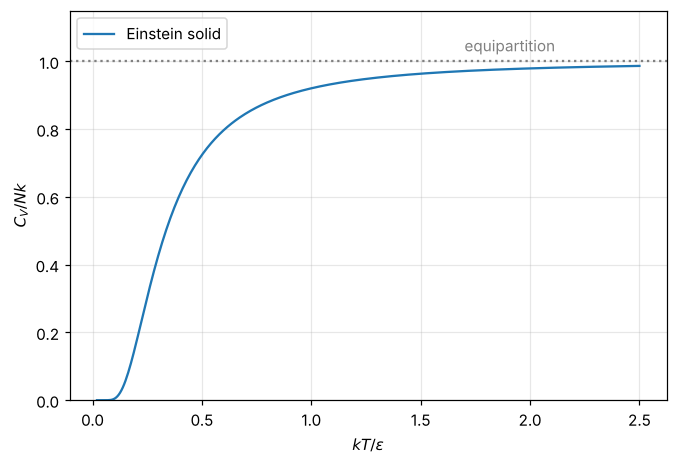

In [4]:
#| label: fig-einstein-heat-capacity
#| caption: "Heat capacity of an Einstein solid derived from S = k ln Ω. At high T it approaches the equipartition value Nk per oscillator (3Nk per atom, Dulong–Petit); at low T the oscillators freeze out and C falls exponentially. Real solids fall more slowly (like T³), which the Debye model of thermo topic 7 explains."
t = np.linspace(0.02, 2.5, 400)       # kT/epsilon
x = 1 / t
C = x**2 * np.exp(x) / np.expm1(x)**2
fig, ax = plt.subplots()
ax.plot(t, C, label="Einstein solid")
ax.axhline(1, ls=":", color="gray"); ax.text(1.7, 1.03, "equipartition", color="gray")
ax.set_xlabel("$kT/\\epsilon$"); ax.set_ylabel("$C_V / Nk$"); ax.set_ylim(0, 1.15); ax.legend(); plt.show()

## Entropy and Heat

When heat $Q$ enters a system slowly at temperature $T$, with no work done, $dU = Q$ and {eq}`eq-temperature-def` gives

$$
dS = \frac{Q}{T}\qquad\text{(quasistatic)} .
$$ (eq-clausius)

This is the Level 1 formula, now a consequence of counting. Combined with $W = -P\,dV$ for quasistatic work, the first law becomes the **thermodynamic identity**

$$
dU = T\,dS - P\,dV + \mu\,dN ,
$$ (eq-thermo-identity)

where the last term (chemical potential, topic 5) accounts for particles entering. It defines $P = T(\partial S/\partial V)_{U,N}$ and $\mu = -T(\partial S/\partial N)_{U,V}$ alongside $1/T$.

## The Ideal Gas and the Entropy of Mixing

Counting states of a monatomic ideal gas (position space times a $3N$-dimensional momentum sphere, divided by $N!$ for identical atoms; T-M2 has the sphere volume) gives the **Sackur–Tetrode equation**:

$$
S = Nk\left[\ln\!\left(\frac VN\left(\frac{4\pi mU}{3Nh^2}\right)^{3/2}\right) + \frac52\right] .
$$ (eq-sackur-tetrode)

Its volume dependence, $S = Nk\ln V + \ldots$, gives $\Delta S = Nk\ln(V_f/V_i)$ for any expansion at fixed $U$, including the *free* expansion of a gas into vacuum, where $Q = 0$ but entropy still rises.

::::{prf:example} Level 1 rung: entropy of mixing
:label: ex-mixing

A box is divided in half, with $N/2$ helium atoms on one side and $N/2$ argon atoms on the other, at the same $T$ and $P$. The partition is removed. Find $\Delta S$.

:::{dropdown} Solution
Each gas doubles its volume at fixed energy, so each gains $(N/2)k\ln2$:

$$
\Delta S_{\text{mixing}} = Nk\ln2 .
$$

If both sides held the *same* gas, removing the partition changes nothing macroscopically, and $\Delta S$ must be zero. The $1/N!$ in the Sackur–Tetrode count is exactly what makes it zero; without it, you get the **Gibbs paradox**, a phantom entropy of mixing for identical gases.
:::
::::

In [5]:
# Sackur-Tetrode: helium at room conditions, compared with the measured third-law value (126 J/(mol K))
m_He = 4.0026 * 1.6605e-27
T, P = 298.15, 1.01325e5
V_per_N = k_B * T / P
U_per_N = 1.5 * k_B * T
S_per_N = k_B * (np.log(V_per_N * (4 * np.pi * m_He * U_per_N / (3 * h**2))**1.5) + 2.5)
display(Math(rf"S_{{\rm He}} = {S_per_N * N_A:.1f}\ \text{{J/(mol K)}}"))

<IPython.core.display.Math object>

## Looking Ahead to Level 3

Pathria derives all of this for a general Hamiltonian: $\Omega$ becomes a phase-space volume (with a factor $h^{3N}N!$), equal probabilities become the microcanonical ensemble, and **Liouville's theorem** shows that the equal-probability assumption is at least consistent with Newton's laws, since phase-space volume flows like an incompressible fluid. The **Gibbs entropy** $S = -k\sum_ip_i\ln p_i$ generalizes $k\ln\Omega$ to unequal probabilities; T-M3 maximizes it to get the Boltzmann distribution.

## Exercises

### Exercises

1. For an Einstein solid with $N = 3$ and $q = 4$, list the $\Omega = 15$ microstates' occupation patterns, and find the probability that a particular oscillator holds all 4 units.
2. Two Einstein solids with $N_A = 300$, $N_B = 200$ share $q = 100$ units. Using the code above as a model, find the most probable $q_A$. How does it compare with $q N_A/(N_A + N_B)$?
3. Using $S/k\approx N\ln(U/N\epsilon) + N$, show $U = NkT$ for the Einstein solid at high temperature. Is this consistent with equipartition?
4. One mole of ideal gas expands freely (into vacuum) to double its volume. Find $\Delta S$ for the gas and for the universe. Then find $\Delta S$ for a slow isothermal doubling, for the gas and for the universe.
5. Use Sackur–Tetrode to find the entropy of argon (40 u) at 298 K and 1 atm, and compare with helium. Why is the heavier gas's entropy higher?

:::{dropdown} Hints
1. Patterns: (4,0,0), (3,1,0), (2,2,0), (2,1,1) and their rearrangements. Count the states with the chosen oscillator at 4.
2. Maximize $\ln\Omega_A + \ln\Omega_B$ numerically.
3. $1/T = \partial S/\partial U$.
4. Entropy is a state function, so the gas's $\Delta S$ is the same both ways. Ask what happens to the reservoir in each case.
5. Only the $m^{3/2}$ inside the logarithm changes.
:::

:::{dropdown} Answers
1. Exactly one microstate has the chosen oscillator at 4, so $P = 1/15$.
2. $q_A = 60$, matching $qN_A/(N_A + N_B)$: energy is shared in proportion to the number of oscillators (equal temperatures).
3. $\partial S/\partial U = Nk/U = 1/T$, so $U = NkT$: two quadratic terms (kinetic and potential) per oscillator, $kT$ each. Yes.
4. Free: gas $+R\ln2 = 5.76$ J/K, universe $+5.76$ J/K (irreversible). Isothermal: gas $+5.76$ J/K, reservoir $-5.76$ J/K, universe 0 (reversible).
5. $S_{\text{Ar}} = S_{\text{He}} + \tfrac32R\ln10\approx 126.0 + 28.7 = 154.7$ J/(mol·K) (measured 154.8). Heavier atoms have more momentum states below the same energy.
:::

## Summary

- Multiplicity counts microstates; for macroscopic systems the most probable macrostate is overwhelmingly so. That is the second law.
- $S = k\ln\Omega$; it adds over subsystems and increases in isolated systems.
- $1/T = (\partial S/\partial U)_{N,V}$; heat flows from hot to cold because that increases total entropy.
- Quasistatic heat gives $dS = Q/T$; the thermodynamic identity is $dU = T\,dS - P\,dV + \mu\,dN$.
- The Einstein solid explains Dulong–Petit and its low-temperature failure; Sackur–Tetrode gives absolute gas entropies, and the $1/N!$ resolves the Gibbs paradox.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.